In [1]:
from google.colab import drive
import os, shutil

drive.mount("/content/drive")

PROJECT_ROOT = "/content/triton-kernel-autotuner"
BACKUP = "/content/drive/MyDrive/triton-kernel-autotuner"

if os.path.isdir(BACKUP + "/src") and os.listdir(BACKUP + "/src"):
    shutil.copytree(BACKUP, PROJECT_ROOT, dirs_exist_ok=True)
    print("RESTORED from Drive backup. Files found:")
    print(sorted(os.listdir(PROJECT_ROOT + "/src")))
    print("\nIf you see environment.py, kernels.py, config_generator.py, verify.py,")
    print("you can SKIP Cells 2, 4, 6 and 7 (the file-writing cells) and go to Cell 3.")
else:
    print("No backup found. Starting fresh.")

for sub in ["src", "results", "notebooks"]:
    os.makedirs(os.path.join(PROJECT_ROOT, sub), exist_ok=True)
print("\nProject folders ready at", PROJECT_ROOT)

Mounted at /content/drive
RESTORED from Drive backup. Files found:
['__pycache__', 'benchmark.py', 'cache.py', 'cached_tuner.py', 'config_generator.py', 'environment.py', 'kernels.py', 'report.py', 'tuner.py', 'verify.py', 'visualization.py']

If you see environment.py, kernels.py, config_generator.py, verify.py,
you can SKIP Cells 2, 4, 6 and 7 (the file-writing cells) and go to Cell 3.

Project folders ready at /content/triton-kernel-autotuner


In [ ]:
%%writefile /content/triton-kernel-autotuner/src/environment.py
"""Environment Manager: inspects the runtime and guards GPU benchmarks."""
import sys
import platform


def get_environment_info() -> dict:
    """Collect software and GPU details. Never raises if CUDA is missing."""
    info = {
        "python_version": sys.version.split()[0],
        "platform": platform.platform(),
    }

    try:
        import torch
        info["torch_version"] = torch.__version__
        info["torch_cuda_build"] = torch.version.cuda
        info["cuda_available"] = torch.cuda.is_available()
    except ImportError:
        info["torch_version"] = None
        info["cuda_available"] = False
        return info

    try:
        import triton
        info["triton_version"] = triton.__version__
    except ImportError:
        info["triton_version"] = None

    if info["cuda_available"]:
        idx = torch.cuda.current_device()
        props = torch.cuda.get_device_properties(idx)
        info["gpu_name"] = props.name
        info["gpu_memory_gb"] = round(props.total_memory / 1024**3, 2)
        info["compute_capability"] = f"{props.major}.{props.minor}"
        info["multiprocessor_count"] = props.multi_processor_count
    return info


def print_environment_info(info: dict) -> None:
    print("=" * 50)
    print(" ENVIRONMENT REPORT")
    print("=" * 50)
    for key, value in info.items():
        print(f"{key:22s}: {value}")
    print("=" * 50)


def require_gpu() -> dict:
    """Return env info if a CUDA GPU + Triton are usable, else raise a clear error."""
    info = get_environment_info()
    if info.get("torch_version") is None:
        raise RuntimeError("PyTorch is not installed in this runtime.")
    if info.get("triton_version") is None:
        raise RuntimeError("Triton is not installed in this runtime.")
    if not info["cuda_available"]:
        raise RuntimeError(
            "No CUDA GPU detected. In Colab: Runtime > Change runtime type > "
            "Hardware accelerator = T4 GPU, then Runtime > Restart session."
        )
    return info

Writing /content/triton-kernel-autotuner/src/environment.py


In [2]:
import sys
sys.path.insert(0, "/content/triton-kernel-autotuner/src")

from environment import get_environment_info, print_environment_info, require_gpu

print_environment_info(get_environment_info())

env = require_gpu()          # raises RuntimeError if no GPU
print(f"\nGPU check passed: {env['gpu_name']} "
      f"({env['gpu_memory_gb']} GB, compute capability {env['compute_capability']})")

 ENVIRONMENT REPORT
python_version        : 3.13.15
platform              : Linux-6.6.122+-x86_64-with-glibc2.39
torch_version         : 2.11.0+cu130
torch_cuda_build      : 13.0
cuda_available        : True
triton_version        : 3.6.0
gpu_name              : Tesla T4
gpu_memory_gb         : 14.56
compute_capability    : 7.5
multiprocessor_count  : 40

GPU check passed: Tesla T4 (14.56 GB, compute capability 7.5)


In [ ]:
%%writefile /content/triton-kernel-autotuner/src/kernels.py
"""Kernel Library: Triton kernels, launch wrappers, and a registry (KernelSpec)."""
from dataclasses import dataclass
from typing import Callable

import torch
import torch.nn.functional as F
import triton
import triton.language as tl


# ================================================================
# Triton kernels
# ================================================================
@triton.jit
def vector_add_kernel(a_ptr, b_ptr, c_ptr, n_elements, BLOCK_SIZE: tl.constexpr):
    """C[i] = A[i] + B[i]"""
    pid = tl.program_id(axis=0)
    offsets = pid * BLOCK_SIZE + tl.arange(0, BLOCK_SIZE)
    mask = offsets < n_elements
    a = tl.load(a_ptr + offsets, mask=mask)
    b = tl.load(b_ptr + offsets, mask=mask)
    tl.store(c_ptr + offsets, a + b, mask=mask)


@triton.jit
def elementwise_mul_kernel(a_ptr, b_ptr, c_ptr, n_elements, BLOCK_SIZE: tl.constexpr):
    """C[i] = A[i] * B[i]"""
    pid = tl.program_id(axis=0)
    offsets = pid * BLOCK_SIZE + tl.arange(0, BLOCK_SIZE)
    mask = offsets < n_elements
    a = tl.load(a_ptr + offsets, mask=mask)
    b = tl.load(b_ptr + offsets, mask=mask)
    tl.store(c_ptr + offsets, a * b, mask=mask)


@triton.jit
def block_sum_kernel(x_ptr, partial_ptr, n_elements, BLOCK_SIZE: tl.constexpr):
    """partial[pid] = sum of the BLOCK_SIZE elements owned by program `pid`."""
    pid = tl.program_id(axis=0)
    offsets = pid * BLOCK_SIZE + tl.arange(0, BLOCK_SIZE)
    mask = offsets < n_elements
    # other=0.0 is essential: masked-out lanes must contribute 0 to the sum,
    # otherwise the last (partial) block would add garbage.
    x = tl.load(x_ptr + offsets, mask=mask, other=0.0)
    tl.store(partial_ptr + pid, tl.sum(x, axis=0))


# ================================================================
# Launch wrappers: (inputs tuple, block_size, num_warps, out) -> out
# ================================================================
def _check_cuda_contiguous(*tensors: torch.Tensor) -> None:
    for t in tensors:
        if not t.is_cuda:
            raise ValueError("Inputs must be CUDA tensors.")
        if not t.is_contiguous():
            raise ValueError("Inputs must be contiguous.")
    if len({(t.shape, t.dtype) for t in tensors}) != 1:
        raise ValueError("Inputs must share shape and dtype.")


def launch_vector_add(inputs, block_size, num_warps, out):
    a, b = inputs
    _check_cuda_contiguous(a, b)
    n = a.numel()
    grid = (triton.cdiv(n, block_size),)
    vector_add_kernel[grid](a, b, out, n, BLOCK_SIZE=block_size, num_warps=num_warps)
    return out


def launch_elementwise_mul(inputs, block_size, num_warps, out):
    a, b = inputs
    _check_cuda_contiguous(a, b)
    n = a.numel()
    grid = (triton.cdiv(n, block_size),)
    elementwise_mul_kernel[grid](a, b, out, n, BLOCK_SIZE=block_size, num_warps=num_warps)
    return out


def launch_block_sum(inputs, block_size, num_warps, out):
    (x,) = inputs
    _check_cuda_contiguous(x)
    n = x.numel()
    grid = (triton.cdiv(n, block_size),)
    block_sum_kernel[grid](x, out, n, BLOCK_SIZE=block_size, num_warps=num_warps)
    return out


# Convenience wrapper used in the smoke test
def vector_add(a, b, block_size: int = 1024, num_warps: int = 4, out=None):
    if out is None:
        out = torch.empty_like(a)
    return launch_vector_add((a, b), block_size, num_warps, out)


# ================================================================
# Input generation, output allocation, trusted references
# ================================================================
def _make_inputs_n(num_inputs):
    def make(n: int, dtype=torch.float32, seed: int = 0):
        g = torch.Generator(device="cuda")
        g.manual_seed(seed)                       # reproducible inputs
        return tuple(torch.randn(n, device="cuda", dtype=dtype, generator=g)
                     for _ in range(num_inputs))
    return make


def _alloc_like_input(inputs, block_size):
    return torch.empty_like(inputs[0])


def _alloc_partials(inputs, block_size):
    n_blocks = triton.cdiv(inputs[0].numel(), block_size)
    return torch.empty(n_blocks, device="cuda", dtype=inputs[0].dtype)


def _ref_add(inputs, block_size):
    return inputs[0] + inputs[1]


def _ref_mul(inputs, block_size):
    return inputs[0] * inputs[1]


def _ref_block_sum(inputs, block_size):
    """float64 per-block sums computed by PyTorch (zero-padded last block)."""
    x = inputs[0].double()
    n_blocks = triton.cdiv(x.numel(), block_size)
    padded = F.pad(x, (0, n_blocks * block_size - x.numel()))
    return padded.view(n_blocks, block_size).sum(dim=1)


# ================================================================
# Registry
# ================================================================
@dataclass(frozen=True)
class KernelSpec:
    name: str
    version: str            # bump when the kernel code changes (used by the cache later)
    launch: Callable        # (inputs, block_size, num_warps, out) -> out
    make_inputs: Callable   # (n, dtype, seed) -> tuple of CUDA tensors
    alloc_output: Callable  # (inputs, block_size) -> tensor
    reference: Callable     # (inputs, block_size) -> trusted expected output
    bytes_moved: Callable   # (n, itemsize, block_size) -> bytes read + written
    rtol: float
    atol: float


REGISTRY = {
    "vector_add": KernelSpec(
        name="vector_add", version="1", launch=launch_vector_add,
        make_inputs=_make_inputs_n(2), alloc_output=_alloc_like_input,
        reference=_ref_add, bytes_moved=lambda n, s, b: 3 * n * s,
        rtol=1e-5, atol=1e-6),
    "elementwise_mul": KernelSpec(
        name="elementwise_mul", version="1", launch=launch_elementwise_mul,
        make_inputs=_make_inputs_n(2), alloc_output=_alloc_like_input,
        reference=_ref_mul, bytes_moved=lambda n, s, b: 3 * n * s,
        rtol=1e-5, atol=1e-6),
    "block_sum": KernelSpec(
        name="block_sum", version="1", launch=launch_block_sum,
        make_inputs=_make_inputs_n(1), alloc_output=_alloc_partials,
        reference=_ref_block_sum,
        bytes_moved=lambda n, s, b: n * s + ((n + b - 1) // b) * s,
        rtol=1e-4, atol=1e-3),   # float32 sums are not bit-exact vs float64
}

Writing /content/triton-kernel-autotuner/src/kernels.py


In [ ]:
import importlib, itertools
import torch
import triton.testing as ttesting

import kernels
importlib.reload(kernels)
from kernels import vector_add

torch.manual_seed(0)

print("Test 1: correctness on awkward sizes (block=256, warps=4)")
for n in [1, 17, 1000, 10_000, 1_000_003]:
    a = torch.randn(n, device="cuda", dtype=torch.float32)
    b = torch.randn(n, device="cuda", dtype=torch.float32)
    out = vector_add(a, b, block_size=256, num_warps=4)
    ok = torch.allclose(out, a + b)
    print(f"  n={n:>9,}  correct={ok}")
    assert ok, f"Mismatch at n={n}"

print("\nTest 2: all candidate configurations (n=1,000,003)")
n = 1_000_003
a = torch.randn(n, device="cuda"); b = torch.randn(n, device="cuda")
ref = a + b
for block, warps in itertools.product([128, 256, 512, 1024], [4, 8]):
    try:
        out = vector_add(a, b, block_size=block, num_warps=warps)
        torch.cuda.synchronize()
        print(f"  block={block:>4}, warps={warps}  correct={torch.allclose(out, ref)}")
    except Exception as e:
        print(f"  block={block:>4}, warps={warps}  FAILED: {type(e).__name__}: {e}")

print("\nTest 3: timing preview with triton.testing.do_bench")
out = torch.empty_like(a)
ms = ttesting.do_bench(
    lambda: vector_add(a, b, 1024, 4, out=out),
    warmup=25, rep=100, return_mode="median",
)
print(f"  median kernel time (block=1024, warps=4): {ms:.4f} ms")
bytes_moved = 3 * n * 4
print(f"  effective bandwidth: {bytes_moved / (ms * 1e-3) / 1e9:.1f} GB/s "
      f"(T4 peak is roughly 320 GB/s)")

Test 1: correctness on awkward sizes (block=256, warps=4)
  n=        1  correct=True
  n=       17  correct=True
  n=    1,000  correct=True
  n=   10,000  correct=True
  n=1,000,003  correct=True

Test 2: all candidate configurations (n=1,000,003)
  block= 128, warps=4  correct=True
  block= 128, warps=8  correct=True
  block= 256, warps=4  correct=True
  block= 256, warps=8  correct=True
  block= 512, warps=4  correct=True
  block= 512, warps=8  correct=True
  block=1024, warps=4  correct=True
  block=1024, warps=8  correct=True

Test 3: timing preview with triton.testing.do_bench
  median kernel time (block=1024, warps=4): 0.0676 ms
  effective bandwidth: 177.6 GB/s (T4 peak is roughly 320 GB/s)


In [ ]:
%%writefile /content/triton-kernel-autotuner/src/verify.py
"""Correctness verification. Every outcome (success OR failure) is recorded."""
import time
from dataclasses import dataclass
from typing import Optional

import torch

from config_generator import Config, validate_config


@dataclass
class VerificationResult:
    config: Config
    compiled: bool                      # did the first launch run without error?
    correct: bool                       # did the output match the PyTorch reference?
    max_abs_error: Optional[float]
    first_call_ms: Optional[float]      # wall-clock of 1st call (includes JIT compile)
    error_type: str = ""
    error_message: str = ""

    def to_dict(self) -> dict:
        d = self.config.to_dict()
        d.update(compiled=self.compiled, correct=self.correct,
                 max_abs_error=self.max_abs_error, first_call_ms=self.first_call_ms,
                 error_type=self.error_type, error_message=self.error_message)
        return d


def verify_config(spec, inputs, cfg: Config) -> VerificationResult:
    """Launch `spec` once with `cfg`, then compare against spec.reference."""
    ok, reason = validate_config(cfg)
    if not ok:
        return VerificationResult(cfg, False, False, None, None, "InvalidConfig", reason)

    try:
        out = spec.alloc_output(inputs, cfg.block_size)
        out.fill_(float("nan"))         # poison: a kernel that forgets to write will fail
        torch.cuda.synchronize()

        t0 = time.perf_counter()
        spec.launch(inputs, cfg.block_size, cfg.num_warps, out)   # 1st call: compiles
        torch.cuda.synchronize()                                   # wait for the GPU to finish
        first_call_ms = (time.perf_counter() - t0) * 1e3
    except Exception as e:              # compile failure, bad launch config, etc.
        return VerificationResult(cfg, False, False, None, None,
                                  type(e).__name__, str(e)[:300])

    try:
        expected = spec.reference(inputs, cfg.block_size)
        got = out.double()
        exp = expected.double()
        correct = bool(torch.allclose(got, exp, rtol=spec.rtol, atol=spec.atol))
        max_err = float((got - exp).abs().max().item())
        msg = "" if correct else f"output differs from reference (max abs err {max_err:.3e})"
        return VerificationResult(cfg, True, correct, max_err, first_call_ms,
                                  "" if correct else "WrongResult", msg)
    except Exception as e:
        return VerificationResult(cfg, True, False, None, first_call_ms,
                                  type(e).__name__, str(e)[:300])

Writing /content/triton-kernel-autotuner/src/verify.py


In [ ]:
import os
src = "/content/triton-kernel-autotuner/src"
print(sorted(os.listdir(src)) if os.path.isdir(src) else "src folder missing")

['__pycache__', 'environment.py', 'kernels.py', 'verify.py']


In [ ]:
%%writefile /content/triton-kernel-autotuner/src/config_generator.py
"""Configuration Generator: candidate launch configurations and validation."""
import itertools
from dataclasses import dataclass, asdict

import triton

MAX_TRITON_BLOCK = 1 << 20     # Triton's limit on elements in one tile (tl.arange)
VALID_WARP_COUNTS = {1, 2, 4, 8, 16, 32}


@dataclass(frozen=True, order=True)
class Config:
    """One launch configuration."""
    block_size: int
    num_warps: int

    def label(self) -> str:
        return f"B{self.block_size}_W{self.num_warps}"

    def to_dict(self) -> dict:
        return asdict(self)


def _is_power_of_two(x: int) -> bool:
    return isinstance(x, int) and x > 0 and (x & (x - 1)) == 0


def validate_config(cfg: Config):
    """Return (is_valid, reason). reason is '' when valid."""
    if not _is_power_of_two(cfg.block_size):
        return False, f"block_size={cfg.block_size} is not a positive power of two (required by tl.arange)"
    if cfg.block_size > MAX_TRITON_BLOCK:
        return False, f"block_size={cfg.block_size} exceeds Triton tile limit {MAX_TRITON_BLOCK}"
    if cfg.num_warps not in VALID_WARP_COUNTS:
        return False, f"num_warps={cfg.num_warps} not in {sorted(VALID_WARP_COUNTS)}"
    return True, ""


def generate_configs(block_sizes=(128, 256, 512, 1024), warp_counts=(4, 8)):
    """Cartesian product of the search space.

    Returns (valid_configs, rejected) where `rejected` is a list of
    {"config": Config, "reason": str}. Nothing is dropped silently.
    """
    valid, rejected, seen = [], [], set()
    for b, w in itertools.product(block_sizes, warp_counts):
        cfg = Config(b, w)
        if cfg in seen:
            continue                       # ignore duplicates in user input
        seen.add(cfg)
        ok, reason = validate_config(cfg)
        if ok:
            valid.append(cfg)
        else:
            rejected.append({"config": cfg, "reason": reason})
    return valid, rejected


def grid_size(n_elements: int, cfg: Config) -> int:
    """Number of program instances launched for n_elements."""
    return triton.cdiv(n_elements, cfg.block_size)

Writing /content/triton-kernel-autotuner/src/config_generator.py


In [ ]:
import os
print(sorted(os.listdir("/content/triton-kernel-autotuner/src")))

['__pycache__', 'config_generator.py', 'environment.py', 'kernels.py', 'verify.py']


In [ ]:
import sys, importlib, dataclasses
sys.path.insert(0, "/content/triton-kernel-autotuner/src")
import pandas as pd
import torch

import kernels, config_generator, verify
for m in (kernels, config_generator, verify):     # reload in dependency order
    importlib.reload(m)

from environment import require_gpu
from kernels import REGISTRY
from config_generator import generate_configs, grid_size
from verify import verify_config

require_gpu()
pd.set_option("display.width", 200)

# ---------- A. Config generator, including deliberately bad input ----------
print("A1. Default search space")
valid, rejected = generate_configs([128, 256, 512, 1024], [4, 8])
print(f"   valid={len(valid)}  rejected={len(rejected)}")

print("\nA2. Search space with intentionally invalid values")
valid_t, rejected_t = generate_configs([128, 1000, 2**21], [4, 3, 8])
print("   valid   :", [c.label() for c in valid_t])
for r in rejected_t:
    print(f"   REJECTED {r['config'].label():>12}: {r['reason']}")

# ---------- B. Verify every kernel x size x config ----------
SIZES = [10_000, 100_000, 1_000_003]
rows = []
for kname, spec in REGISTRY.items():
    for n in SIZES:
        inputs = spec.make_inputs(n, torch.float32, seed=0)
        for cfg in valid:
            d = verify_config(spec, inputs, cfg).to_dict()
            d.update(kernel=kname, n=n, grid=grid_size(n, cfg))
            rows.append(d)
df = pd.DataFrame(rows)

print("\nB1. Summary (configs correct / configs tried)")
summary = df.groupby(["kernel", "n"]).agg(
    tried=("correct", "size"), correct=("correct", "sum"),
    worst_abs_err=("max_abs_error", "max"))
print(summary)

print("\nB2. Failures (empty table = none)")
failed = df[~df["correct"]]
print(failed[["kernel", "n", "block_size", "num_warps", "error_type", "error_message"]]
      if len(failed) else "   none")

print("\nB3. First-call (compile + run) time, vector_add, n=1,000,003")
sub = df[(df.kernel == "vector_add") & (df.n == 1_000_003)]
print(sub[["block_size", "num_warps", "grid", "first_call_ms"]].to_string(index=False))

# ---------- C. Can the verifier catch a WRONG kernel? ----------
print("\nC. Negative test: reference deliberately off by +1.0")
bad_spec = dataclasses.replace(
    REGISTRY["vector_add"], reference=lambda inputs, b: inputs[0] + inputs[1] + 1.0)
inputs = bad_spec.make_inputs(10_000)
r = verify_config(bad_spec, inputs, valid[0])
print(f"   compiled={r.compiled} correct={r.correct} "
      f"error_type={r.error_type}\n   {r.error_message}")

df.to_csv("/content/triton-kernel-autotuner/results/phase2_verification.csv", index=False)

A1. Default search space
   valid=8  rejected=0

A2. Search space with intentionally invalid values
   valid   : ['B128_W4', 'B128_W8']
   REJECTED      B128_W3: num_warps=3 not in [1, 2, 4, 8, 16, 32]
   REJECTED     B1000_W4: block_size=1000 is not a positive power of two (required by tl.arange)
   REJECTED     B1000_W3: block_size=1000 is not a positive power of two (required by tl.arange)
   REJECTED     B1000_W8: block_size=1000 is not a positive power of two (required by tl.arange)
   REJECTED  B2097152_W4: block_size=2097152 exceeds Triton tile limit 1048576
   REJECTED  B2097152_W3: block_size=2097152 exceeds Triton tile limit 1048576
   REJECTED  B2097152_W8: block_size=2097152 exceeds Triton tile limit 1048576

B1. Summary (configs correct / configs tried)
                         tried  correct  worst_abs_err
kernel          n                                     
block_sum       10000        8        8       0.000009
                100000       8        8       0.000009
   

In [ ]:
import shutil
shutil.copytree("/content/triton-kernel-autotuner",
                "/content/drive/MyDrive/triton-kernel-autotuner", dirs_exist_ok=True)
print("Backed up to Drive.")

Backed up to Drive.


In [ ]:
%%writefile /content/triton-kernel-autotuner/src/benchmark.py
"""Benchmarking: steady-state kernel timing, kept separate from compile time."""
import statistics
import time
from dataclasses import dataclass

import torch
import triton.testing as ttesting


@dataclass(frozen=True)
class BenchSettings:
    warmup_ms: float = 25.0      # do_bench warm-up duration (milliseconds, NOT iterations)
    rep_ms: float = 50.0         # do_bench measurement duration per repeat (milliseconds)
    repeats: int = 5             # independent do_bench runs per configuration (search phase)
    confirm_repeats: int = 15    # runs per config in the final head-to-head re-measurement


def _stats(samples):
    med = statistics.median(samples)
    spread = 100.0 * (max(samples) - min(samples)) / med if med > 0 else 0.0
    return {
        "median_ms": med,
        "min_ms": min(samples),
        "max_ms": max(samples),
        "std_ms": statistics.pstdev(samples) if len(samples) > 1 else 0.0,
        "spread_pct": spread,          # (max-min)/median: a conservative noise estimate
        "samples": list(samples),
    }


def time_kernel_once(spec, inputs, cfg, out, settings: BenchSettings) -> float:
    """One do_bench run -> median kernel time in ms.

    do_bench times with CUDA events and synchronizes internally, so we do not add
    our own synchronize here. Only the kernel launch is inside the timed lambda.
    """
    fn = lambda: spec.launch(inputs, cfg.block_size, cfg.num_warps, out)
    return ttesting.do_bench(fn, warmup=settings.warmup_ms, rep=settings.rep_ms,
                             return_mode="median")


def benchmark_config(spec, inputs, cfg, settings: BenchSettings):
    """Repeat do_bench several times; return robust statistics + bandwidth."""
    out = spec.alloc_output(inputs, cfg.block_size)     # allocated OUTSIDE the timed region
    samples = [time_kernel_once(spec, inputs, cfg, out, settings)
               for _ in range(settings.repeats)]
    st = _stats(samples)
    n = inputs[0].numel()
    nbytes = spec.bytes_moved(n, inputs[0].element_size(), cfg.block_size)
    st["bandwidth_gbs"] = nbytes / (st["median_ms"] * 1e-3) / 1e9
    return st


def head_to_head(spec, inputs, cfg_a, cfg_b, settings: BenchSettings):
    """Re-measure two configs INTERLEAVED (A,B,A,B,...) so slow drift in GPU clocks
    or contention affects both equally. Returns (stats_a, stats_b)."""
    out_a = spec.alloc_output(inputs, cfg_a.block_size)
    out_b = spec.alloc_output(inputs, cfg_b.block_size)
    sa, sb = [], []
    for _ in range(settings.confirm_repeats):
        sa.append(time_kernel_once(spec, inputs, cfg_a, out_a, settings))
        sb.append(time_kernel_once(spec, inputs, cfg_b, out_b, settings))
    return _stats(sa), _stats(sb)


def measure_end_to_end(spec, inputs, cfg, iters: int = 50) -> float:
    """End-to-end latency (ms): allocate output + Python launch + GPU run + synchronize.
    This is what an application experiences, and it is NOT the same as kernel latency."""
    for _ in range(3):                                   # warm-up
        spec.launch(inputs, cfg.block_size, cfg.num_warps,
                    spec.alloc_output(inputs, cfg.block_size))
    torch.cuda.synchronize()
    samples = []
    for _ in range(iters):
        torch.cuda.synchronize()                         # start from an idle GPU
        t0 = time.perf_counter()
        out = spec.alloc_output(inputs, cfg.block_size)
        spec.launch(inputs, cfg.block_size, cfg.num_warps, out)
        torch.cuda.synchronize()                         # wait until the GPU finishes
        samples.append((time.perf_counter() - t0) * 1e3)
    return statistics.median(samples)

Writing /content/triton-kernel-autotuner/src/benchmark.py


In [ ]:
%%writefile /content/triton-kernel-autotuner/src/tuner.py
"""Auto-Tuning Engine: exhaustive search over launch configurations."""
import datetime
import time
from dataclasses import dataclass
from typing import Optional

import torch

from benchmark import BenchSettings, benchmark_config, head_to_head, measure_end_to_end
from config_generator import Config, grid_size
from environment import require_gpu
from verify import verify_config

DEFAULT_BASELINE = Config(block_size=1024, num_warps=4)


def _now() -> str:
    return datetime.datetime.now().isoformat(timespec="seconds")


@dataclass
class TuneResult:
    kernel: str
    n: int
    gpu: str
    algorithm: str
    records: list                       # one dict per attempted config (incl. failures)
    best: Optional[Config]
    attempted: int
    successful: int
    failed: int
    tuning_time_s: float                # search phase only (includes compile + verify + timing)
    baseline: Config
    confirm_time_s: float = 0.0         # head-to-head re-measurement (reported separately)
    search_best_ms: Optional[float] = None   # best latency seen DURING the search
    baseline_ms: Optional[float] = None      # head-to-head median
    tuned_ms: Optional[float] = None         # head-to-head median
    baseline_spread_pct: Optional[float] = None
    tuned_spread_pct: Optional[float] = None
    improvement_pct: Optional[float] = None
    verdict: str = ""
    e2e_baseline_ms: Optional[float] = None
    e2e_tuned_ms: Optional[float] = None

    def summary_row(self) -> dict:
        return {
            "kernel": self.kernel, "n": self.n, "gpu": self.gpu,
            "algorithm": self.algorithm,
            "best_block": self.best.block_size if self.best else None,
            "best_warps": self.best.num_warps if self.best else None,
            "attempted": self.attempted, "successful": self.successful, "failed": self.failed,
            "search_best_ms": self.search_best_ms,
            "baseline_cfg": self.baseline.label(),
            "baseline_ms": self.baseline_ms, "tuned_ms": self.tuned_ms,
            "improvement_pct": self.improvement_pct,
            "baseline_spread_pct": self.baseline_spread_pct,
            "tuned_spread_pct": self.tuned_spread_pct,
            "verdict": self.verdict,
            "tuning_time_s": self.tuning_time_s, "confirm_time_s": self.confirm_time_s,
            "e2e_baseline_ms": self.e2e_baseline_ms, "e2e_tuned_ms": self.e2e_tuned_ms,
        }


def evaluate_config(spec, inputs, cfg: Config, settings: BenchSettings,
                    gpu: str, algorithm: str) -> dict:
    """Verify one config, then benchmark it if (and only if) it is correct.
    Returns a flat record. Failures are recorded, never dropped."""
    n = inputs[0].numel()
    rec = {
        "kernel": spec.name, "kernel_version": spec.version, "n": n, "gpu": gpu,
        "block_size": cfg.block_size, "num_warps": cfg.num_warps,
        "grid": grid_size(n, cfg), "search_algorithm": algorithm,
        "trials": settings.repeats, "timestamp": _now(),
        "compiled": False, "correct": False, "status": "failed",
        "first_call_ms": None, "latency_ms": None, "latency_min_ms": None,
        "latency_max_ms": None, "latency_std_ms": None, "spread_pct": None,
        "bandwidth_gbs": None, "error_type": "", "error_message": "",
    }
    v = verify_config(spec, inputs, cfg)
    rec.update(compiled=v.compiled, correct=v.correct, first_call_ms=v.first_call_ms,
               error_type=v.error_type, error_message=v.error_message)
    if not (v.compiled and v.correct):
        return rec                                   # recorded as failed, no timing

    try:
        st = benchmark_config(spec, inputs, cfg, settings)
    except Exception as e:                           # timing itself failed
        rec.update(error_type=type(e).__name__, error_message=str(e)[:300])
        return rec

    rec.update(status="ok", latency_ms=st["median_ms"], latency_min_ms=st["min_ms"],
               latency_max_ms=st["max_ms"], latency_std_ms=st["std_ms"],
               spread_pct=st["spread_pct"], bandwidth_gbs=st["bandwidth_gbs"])
    return rec


def _finalize(spec, inputs, n, gpu, algorithm, records, tuning_time_s,
              settings, baseline) -> TuneResult:
    """Rank, pick the best, then compare against the baseline head-to-head."""
    ok = sorted((r for r in records if r["status"] == "ok"), key=lambda r: r["latency_ms"])
    for rank, r in enumerate(ok, start=1):
        r["rank"] = rank
    for r in records:
        r.setdefault("rank", None)

    res = TuneResult(kernel=spec.name, n=n, gpu=gpu, algorithm=algorithm, records=records,
                     best=None, attempted=len(records), successful=len(ok),
                     failed=len(records) - len(ok), tuning_time_s=tuning_time_s,
                     baseline=baseline)
    if not ok:
        res.verdict = "no valid configuration found"
        return res

    best = Config(ok[0]["block_size"], ok[0]["num_warps"])
    res.best = best
    res.search_best_ms = ok[0]["latency_ms"]

    # The baseline must itself be correct, otherwise comparing against it is meaningless.
    if not verify_config(spec, inputs, baseline).correct:
        res.verdict = "baseline config failed verification; no comparison made"
        return res

    t0 = time.perf_counter()
    base_st, best_st = head_to_head(spec, inputs, baseline, best, settings)
    res.confirm_time_s = time.perf_counter() - t0
    res.baseline_ms, res.tuned_ms = base_st["median_ms"], best_st["median_ms"]
    res.baseline_spread_pct, res.tuned_spread_pct = base_st["spread_pct"], best_st["spread_pct"]
    res.improvement_pct = 100.0 * (res.baseline_ms - res.tuned_ms) / res.baseline_ms
    res.e2e_baseline_ms = measure_end_to_end(spec, inputs, baseline)
    res.e2e_tuned_ms = measure_end_to_end(spec, inputs, best)

    noise = max(res.baseline_spread_pct, res.tuned_spread_pct)
    if best == baseline:
        res.verdict = "best config equals baseline (difference shown is pure measurement noise)"
    elif abs(res.improvement_pct) <= noise:
        res.verdict = f"difference is within measurement noise (~{noise:.1f}% spread)"
    elif res.improvement_pct > 0:
        res.verdict = "tuned config measurably faster than baseline"
    else:
        res.verdict = "tuned config measurably SLOWER than baseline"
    return res


def exhaustive_search(spec, n: int, configs, settings: BenchSettings = BenchSettings(),
                      baseline: Config = DEFAULT_BASELINE, dtype=torch.float32,
                      seed: int = 0) -> TuneResult:
    """Test EVERY candidate configuration. The best is the fastest among the valid
    configurations tested for this kernel, size and GPU (not a proven global optimum)."""
    gpu = require_gpu()["gpu_name"]                  # refuses to run without a GPU
    inputs = spec.make_inputs(n, dtype, seed)

    t0 = time.perf_counter()
    records = [evaluate_config(spec, inputs, cfg, settings, gpu, "exhaustive")
               for cfg in configs]
    tuning_time_s = time.perf_counter() - t0

    return _finalize(spec, inputs, n, gpu, "exhaustive", records, tuning_time_s,
                     settings, baseline)

Writing /content/triton-kernel-autotuner/src/tuner.py


In [ ]:
import sys, importlib
sys.path.insert(0, "/content/triton-kernel-autotuner/src")
import pandas as pd
import torch

import kernels, config_generator, verify, benchmark, tuner
for m in (kernels, config_generator, verify, benchmark, tuner):
    importlib.reload(m)

from kernels import REGISTRY
from config_generator import generate_configs
from benchmark import BenchSettings
from tuner import exhaustive_search

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)

configs, _ = generate_configs([128, 256, 512, 1024], [4, 8])
res = exhaustive_search(REGISTRY["vector_add"], 1_000_003, configs, BenchSettings())

df = pd.DataFrame(res.records).sort_values("rank")
print("Ranking (vector_add, n=1,000,003):")
print(df[["rank", "block_size", "num_warps", "grid", "latency_ms",
          "spread_pct", "bandwidth_gbs", "first_call_ms", "status"]].to_string(index=False))

print(f"\nAttempted={res.attempted}  Successful={res.successful}  Failed={res.failed}")
print(f"Best (fastest tested): block={res.best.block_size}, warps={res.best.num_warps}")
print(f"\nBaseline {res.baseline.label()}: {res.baseline_ms:.4f} ms   (spread {res.baseline_spread_pct:.1f}%)")
print(f"Tuned    {res.best.label()}: {res.tuned_ms:.4f} ms   (spread {res.tuned_spread_pct:.1f}%)")
print(f"Improvement: {res.improvement_pct:+.2f}%   -> {res.verdict}")
print(f"\nTuning time (search): {res.tuning_time_s:.2f} s | confirmation: {res.confirm_time_s:.2f} s")
print(f"End-to-end latency: baseline {res.e2e_baseline_ms:.4f} ms, tuned {res.e2e_tuned_ms:.4f} ms")

Ranking (vector_add, n=1,000,003):
 rank  block_size  num_warps  grid  latency_ms  spread_pct  bandwidth_gbs  first_call_ms status
    1         256          8  3907    0.051840    0.679018     231.482177       6.028348     ok
    2         128          4  7813    0.053216    0.120265     225.496771       4.585069     ok
    3         512          8  1954    0.054112    1.241871     221.762942       1.911832     ok
    4         128          8  7813    0.054176    0.767867     221.500964       1.869886     ok
    5         256          4  3907    0.054560    1.759531     219.942016       2.359262     ok
    6        1024          4   977    0.063488    0.252018     189.012666       1.988119     ok
    7         512          4  1954    0.065056    0.491876     184.457011       2.064918     ok
    8        1024          8   977    0.067312    0.427862     178.274844       2.420210     ok

Attempted=8  Successful=8  Failed=0
Best (fastest tested): block=256, warps=8

Baseline B1024_W4: 0.

In [ ]:
import time
from kernels import REGISTRY

SIZES = [10_000, 100_000, 1_000_003]
all_records, summaries = [], []

t_total = time.perf_counter()
for kname, spec in REGISTRY.items():
    for n in SIZES:
        r = exhaustive_search(spec, n, configs, BenchSettings())
        all_records += r.records
        summaries.append(r.summary_row())
        print(f"done {kname:16s} n={n:>9,}  best={r.best.label():9s} "
              f"improvement={r.improvement_pct:+6.2f}%  ({r.verdict})")
print(f"\nTotal wall time: {time.perf_counter() - t_total:.1f} s")

df_records = pd.DataFrame(all_records)
df_summary = pd.DataFrame(summaries)

cols = ["kernel", "n", "best_block", "best_warps", "baseline_ms", "tuned_ms",
        "improvement_pct", "baseline_spread_pct", "tuned_spread_pct",
        "tuning_time_s", "e2e_baseline_ms", "e2e_tuned_ms"]
print()
print(df_summary[cols].round(4).to_string(index=False))

R = "/content/triton-kernel-autotuner/results/"
df_records.to_csv(R + "phase3_all_records.csv", index=False)
df_summary.to_csv(R + "phase3_summary.csv", index=False)
print("\nSaved phase3_all_records.csv and phase3_summary.csv")

done vector_add       n=   10,000  best=B1024_W4  improvement= +0.70%  (best config equals baseline (difference shown is pure measurement noise))
done vector_add       n=  100,000  best=B128_W4   improvement= +1.93%  (difference is within measurement noise (~5.1% spread))
done vector_add       n=1,000,003  best=B128_W4   improvement=+18.65%  (tuned config measurably faster than baseline)
done elementwise_mul  n=   10,000  best=B1024_W8  improvement= +2.80%  (difference is within measurement noise (~8.4% spread))
done elementwise_mul  n=  100,000  best=B256_W8   improvement= +3.18%  (tuned config measurably faster than baseline)
done elementwise_mul  n=1,000,003  best=B128_W4   improvement=+18.69%  (tuned config measurably faster than baseline)
done block_sum        n=   10,000  best=B512_W4   improvement= +0.73%  (difference is within measurement noise (~10.2% spread))
done block_sum        n=  100,000  best=B512_W8   improvement= -0.47%  (difference is within measurement noise (~10.4%

In [ ]:
%%writefile /content/triton-kernel-autotuner/src/cache.py
"""JSON tuning cache: stable keys, hit/miss tracking, versioning, safe load/save."""
import datetime
import hashlib
import json
import os

CACHE_SCHEMA_VERSION = 1      # bump if the structure of this file's JSON changes


def now_iso() -> str:
    return datetime.datetime.now().isoformat(timespec="seconds")


def build_key_components(spec, n, dtype, env, configs, baseline,
                         algorithm="exhaustive", algo_params=None) -> dict:
    """Everything that could change which config is fastest, or whether a stored
    result can be trusted. If ANY of these differ, the cache must miss."""
    return {
        "kernel": spec.name,
        "kernel_version": spec.version,
        "shape": [int(n)],
        "dtype": str(dtype).replace("torch.", ""),
        "gpu_name": env["gpu_name"],
        "compute_capability": env["compute_capability"],
        "triton_version": env["triton_version"],
        "torch_cuda_build": env["torch_cuda_build"],
        "search_space": sorted([c.block_size, c.num_warps] for c in configs),
        "baseline": [baseline.block_size, baseline.num_warps],
        "algorithm": algorithm,
        "algo_params": algo_params or {},
    }


def make_cache_key(components: dict) -> str:
    """Stable key: readable kernel name + SHA-256 of the canonical JSON of components."""
    canonical = json.dumps(components, sort_keys=True, separators=(",", ":"))
    digest = hashlib.sha256(canonical.encode("utf-8")).hexdigest()[:16]
    return f"{components['kernel']}-{digest}"


def _entry_is_well_formed(entry) -> bool:
    try:
        bc = entry["best_config"]
        return (isinstance(entry["key_components"], dict)
                and isinstance(bc["block_size"], int)
                and isinstance(bc["num_warps"], int)
                and isinstance(entry["measured"], dict)
                and isinstance(entry["search"], dict))
    except (KeyError, TypeError):
        return False


class TuningCache:
    def __init__(self, path: str):
        self.path = path
        self.session_hits = 0
        self.session_misses = 0
        self.data = self._load()

    # ---------------- loading / saving ----------------
    @staticmethod
    def _empty() -> dict:
        return {"schema_version": CACHE_SCHEMA_VERSION, "created_at": now_iso(), "entries": {}}

    def _quarantine(self, reason: str) -> None:
        """Move an unusable cache file aside (never delete user data)."""
        stamp = datetime.datetime.now().strftime("%Y%m%d-%H%M%S")
        backup = f"{self.path}.corrupt-{stamp}"
        try:
            os.replace(self.path, backup)
            where = f"Moved the old file to {os.path.basename(backup)}"
        except OSError:
            where = "Could not move the old file"
        print(f"[cache] WARNING: {reason}. {where}; starting with an empty cache.")

    def _load(self) -> dict:
        if not os.path.exists(self.path):
            return self._empty()
        try:
            with open(self.path, "r", encoding="utf-8") as f:
                data = json.load(f)
        except (ValueError, OSError) as e:      # JSONDecodeError/UnicodeDecodeError are ValueErrors
            self._quarantine(f"cache file is not valid JSON ({type(e).__name__})")
            return self._empty()
        if not isinstance(data, dict) or not isinstance(data.get("entries"), dict):
            self._quarantine("cache file has an unexpected structure")
            return self._empty()
        if data.get("schema_version") != CACHE_SCHEMA_VERSION:
            self._quarantine(f"cache schema version {data.get('schema_version')} "
                             f"!= expected {CACHE_SCHEMA_VERSION}")
            return self._empty()
        return data

    def save(self) -> None:
        """Atomic save: write a temp file, then swap it in."""
        folder = os.path.dirname(self.path)
        if folder:
            os.makedirs(folder, exist_ok=True)
        tmp = self.path + ".tmp"
        with open(tmp, "w", encoding="utf-8") as f:
            json.dump(self.data, f, indent=2, sort_keys=True)
        os.replace(tmp, self.path)

    # ---------------- lookup / insert ----------------
    def lookup(self, components: dict):
        """Return (key, entry_or_None, reason_if_none). Does NOT change counters."""
        key = make_cache_key(components)
        entry = self.data["entries"].get(key)
        if entry is None:
            return key, None, "no entry for this key"
        if not _entry_is_well_formed(entry):
            return key, None, "stored entry is malformed"
        if entry["key_components"] != components:
            return key, None, "stored key components differ (hash collision or edited file)"
        return key, entry, ""

    def record_hit(self, key: str) -> None:
        entry = self.data["entries"][key]
        entry["hits"] = int(entry.get("hits", 0)) + 1
        entry["last_hit_at"] = now_iso()
        self.session_hits += 1
        self.save()

    def record_miss(self) -> None:
        self.session_misses += 1

    def insert(self, key: str, entry: dict) -> None:
        self.data["entries"][key] = entry
        self.save()

    # ---------------- invalidation ----------------
    def invalidate(self, kernel=None, kernel_version=None, gpu_name=None) -> int:
        """Delete entries matching ALL given filters. Returns how many were removed."""
        def matches(entry):
            kc = entry.get("key_components", {}) if isinstance(entry, dict) else {}
            return ((kernel is None or kc.get("kernel") == kernel)
                    and (kernel_version is None or kc.get("kernel_version") == kernel_version)
                    and (gpu_name is None or kc.get("gpu_name") == gpu_name))
        doomed = [k for k, e in self.data["entries"].items() if matches(e)]
        for k in doomed:
            del self.data["entries"][k]
        self.save()
        return len(doomed)

    def clear(self) -> None:
        self.data["entries"] = {}
        self.save()

    # ---------------- reporting ----------------
    def summary_rows(self) -> list:
        rows = []
        for key, e in self.data["entries"].items():
            kc = e.get("key_components", {})
            bc = e.get("best_config", {})
            rows.append({
                "kernel": kc.get("kernel"), "version": kc.get("kernel_version"),
                "n": (kc.get("shape") or [None])[0], "gpu": kc.get("gpu_name"),
                "algorithm": kc.get("algorithm"),
                "best_block": bc.get("block_size"), "best_warps": bc.get("num_warps"),
                "improvement_pct": e.get("measured", {}).get("improvement_pct"),
                "hits": e.get("hits"), "created_at": e.get("created_at"), "key": key,
            })
        return rows

Writing /content/triton-kernel-autotuner/src/cache.py


In [ ]:
%%writefile /content/triton-kernel-autotuner/src/cached_tuner.py
"""Cache-aware tuning: reuse a stored result when it is safe, otherwise search and store."""
import time
from dataclasses import dataclass, asdict
from typing import Optional

import torch

from benchmark import BenchSettings
from cache import TuningCache, build_key_components, now_iso
from config_generator import Config
from environment import require_gpu
from tuner import DEFAULT_BASELINE, TuneResult, exhaustive_search
from verify import verify_config

# Later phases register more strategies here (e.g. "random", "halving").
SEARCH_FUNCTIONS = {"exhaustive": exhaustive_search}


@dataclass
class CachedTuneOutcome:
    status: str                      # hit | miss | stale_retuned | forced_retune | no_valid_config
    best: Optional[Config]
    entry: Optional[dict]            # the stored record (measured/search metadata)
    result: Optional[TuneResult]     # set ONLY when a new search actually ran
    lookup_ms: float
    total_s: float
    message: str


def _entry_from_result(components, res: TuneResult, settings, env) -> dict:
    return {
        "key_components": components,
        "best_config": res.best.to_dict(),
        "measured": {                        # timings measured at `created_at`
            "search_best_ms": res.search_best_ms,
            "baseline_config": res.baseline.to_dict(),
            "baseline_ms": res.baseline_ms,
            "tuned_ms": res.tuned_ms,
            "improvement_pct": res.improvement_pct,
            "baseline_spread_pct": res.baseline_spread_pct,
            "tuned_spread_pct": res.tuned_spread_pct,
            "verdict": res.verdict,
            "e2e_baseline_ms": res.e2e_baseline_ms,
            "e2e_tuned_ms": res.e2e_tuned_ms,
        },
        "search": {
            "algorithm": res.algorithm, "attempted": res.attempted,
            "successful": res.successful, "failed": res.failed,
            "tuning_time_s": res.tuning_time_s, "confirm_time_s": res.confirm_time_s,
        },
        "bench_settings": asdict(settings),
        "environment": {k: env.get(k) for k in (
            "gpu_name", "gpu_memory_gb", "compute_capability", "torch_version",
            "triton_version", "torch_cuda_build", "python_version")},
        "created_at": now_iso(), "hits": 0, "last_hit_at": None,
    }


def tune_with_cache(cache: TuningCache, spec, n: int, configs,
                    algorithm: str = "exhaustive",
                    settings: BenchSettings = BenchSettings(),
                    baseline: Config = DEFAULT_BASELINE, dtype=torch.float32,
                    verify_on_hit: bool = True,
                    force_retune: bool = False) -> CachedTuneOutcome:
    if algorithm not in SEARCH_FUNCTIONS:
        raise ValueError(f"Unknown algorithm '{algorithm}'. Available: {sorted(SEARCH_FUNCTIONS)}")

    t_start = time.perf_counter()
    env = require_gpu()
    components = build_key_components(spec, n, dtype, env, configs, baseline, algorithm)

    t0 = time.perf_counter()
    key, entry, miss_reason = cache.lookup(components)
    lookup_ms = (time.perf_counter() - t0) * 1e3

    status, reason = "miss", miss_reason
    if force_retune:
        status, reason, entry = "forced_retune", "force_retune=True", None

    if entry is not None and verify_on_hit:
        stored = Config(entry["best_config"]["block_size"], entry["best_config"]["num_warps"])
        v = verify_config(spec, spec.make_inputs(n, dtype, 0), stored)
        if not (v.compiled and v.correct):
            status = "stale_retuned"
            reason = f"stored config failed re-verification ({v.error_type}: {v.error_message})"
            entry = None

    # ---------------- HIT: reuse the recorded configuration ----------------
    if entry is not None:
        cache.record_hit(key)
        best = Config(entry["best_config"]["block_size"], entry["best_config"]["num_warps"])
        msg = (f"CACHE HIT: reusing the configuration recorded on {entry['created_at']}. "
               f"The timings stored in the entry were measured THEN, not now. No new benchmark "
               f"was run" + (" (only a one-launch correctness check)." if verify_on_hit else "."))
        return CachedTuneOutcome("hit", best, entry, None, lookup_ms,
                                 time.perf_counter() - t_start, msg)

    # ---------------- MISS: run the search, then store the result ----------------
    cache.record_miss()
    res = SEARCH_FUNCTIONS[algorithm](spec, n, configs, settings=settings,
                                      baseline=baseline, dtype=dtype)
    if res.best is None:
        return CachedTuneOutcome("no_valid_config", None, None, res, lookup_ms,
                                 time.perf_counter() - t_start,
                                 f"CACHE MISS ({reason}); no valid configuration found, nothing stored.")
    entry = _entry_from_result(components, res, settings, env)
    cache.insert(key, entry)
    msg = (f"CACHE MISS ({reason}): ran a NEW {algorithm} search and stored the result. "
           f"These timings are fresh measurements.")
    return CachedTuneOutcome(status, res.best, entry, res, lookup_ms,
                             time.perf_counter() - t_start, msg)

Writing /content/triton-kernel-autotuner/src/cached_tuner.py


In [ ]:
import sys, importlib, dataclasses, json, glob, os
sys.path.insert(0, "/content/triton-kernel-autotuner/src")
import torch
import pandas as pd

import kernels, config_generator, verify, benchmark, tuner, cache, cached_tuner
for m in (kernels, config_generator, verify, benchmark, tuner, cache, cached_tuner):
    importlib.reload(m)

from kernels import REGISTRY
from config_generator import generate_configs
from benchmark import BenchSettings
from tuner import DEFAULT_BASELINE
from cache import TuningCache, build_key_components, make_cache_key
from cached_tuner import tune_with_cache
from environment import require_gpu

pd.set_option("display.width", 220)
CACHE_PATH = "/content/triton-kernel-autotuner/results/autotune_cache.json"
tc = TuningCache(CACHE_PATH)
tc.clear()                                   # clean slate so the demo is reproducible

spec = REGISTRY["vector_add"]
configs, _ = generate_configs([128, 256, 512, 1024], [4, 8])
S = BenchSettings()

def show(title, o):
    print(f"\n--- {title}")
    print(f"status={o.status}  best={o.best.label() if o.best else None}  "
          f"time={o.total_s:.3f} s  (dictionary lookup {o.lookup_ms:.3f} ms)")
    print("  " + o.message)

# 1-2: miss then hit
o1 = tune_with_cache(tc, spec, 1_000_003, configs, settings=S)
show("1. First request (expect MISS: search + store)", o1)
o2 = tune_with_cache(tc, spec, 1_000_003, configs, settings=S)
show("2. Identical request (expect HIT)", o2)
print(f"\n   Time to obtain a config: miss {o1.total_s:.2f} s vs hit {o2.total_s:.3f} s")

# 3-5: anything that changes the key must MISS
show("3. Different input size, n=100,000 (expect MISS)",
     tune_with_cache(tc, spec, 100_000, configs, settings=S))
spec_v2 = dataclasses.replace(spec, version="2")
show("4. Kernel version bumped 1 -> 2 (expect MISS)",
     tune_with_cache(tc, spec_v2, 1_000_003, configs, settings=S))
small, _ = generate_configs([128, 256], [4, 8])
show("5. Smaller search space (expect MISS)",
     tune_with_cache(tc, spec, 1_000_003, small, settings=S))

# 6: a hand-edited / stale entry must not be trusted
env = require_gpu()
comp = build_key_components(spec, 1_000_003, torch.float32, env, configs, DEFAULT_BASELINE)
key = make_cache_key(comp)
tc.data["entries"][key]["best_config"] = {"block_size": 1000, "num_warps": 4}   # invalid on purpose
show("6. Tampered entry (best_config edited to block_size=1000) -> expect stale_retuned",
     tune_with_cache(tc, spec, 1_000_003, configs, settings=S))

# 7: key sensitivity to the GPU (key only; no other GPU was used)
other = dict(comp, gpu_name="NVIDIA A100-SXM4-40GB", compute_capability="8.0")
print("\n--- 7. Key sensitivity to GPU (illustration only, nothing was run on an A100)")
print("   this GPU :", make_cache_key(comp))
print("   other GPU:", make_cache_key(other), "| same key?", make_cache_key(comp) == make_cache_key(other))

# 8: persistence - a brand-new cache object loads the JSON file from disk
tc2 = TuningCache(CACHE_PATH)
show("8. New TuningCache object loaded from disk (expect HIT)",
     tune_with_cache(tc2, spec, 1_000_003, configs, settings=S))

# 9: malformed JSON recovery
bad = "/content/triton-kernel-autotuner/results/demo_corrupt_cache.json"
with open(bad, "w") as f:
    f.write('{"schema_version": 1, "entries": {')          # truncated JSON
tc_bad = TuningCache(bad)
print(f"\n--- 9. Corrupt file recovery: entries after load = {len(tc_bad.data['entries'])}")
for p in glob.glob(bad + "*"):
    os.remove(p)                                            # tidy up the demo files

# 10: contents and amortization
print("\n--- 10. Cache contents")
print(pd.DataFrame(tc.summary_rows()).drop(columns=["key"]).to_string(index=False))
print(f"\nSession counters (first cache object): hits={tc.session_hits}, misses={tc.session_misses}")

r = o1.result
saving_ms = r.baseline_ms - r.tuned_ms
if saving_ms > 0:
    cost_s = r.tuning_time_s + r.confirm_time_s
    print(f"\nAmortization (kernel latency only): saves {saving_ms:.5f} ms per launch; "
          f"tuning + confirmation cost {cost_s:.2f} s -> break-even after about "
          f"{cost_s / (saving_ms * 1e-3):,.0f} launches.")
else:
    print("\nTuned config was not faster than baseline here, so there is no break-even point.")

print("\n--- First lines of autotune_cache.json")
print("\n".join(open(CACHE_PATH).read().splitlines()[:45]))


--- 1. First request (expect MISS: search + store)
status=miss  best=B256_W8  time=4.063 s  (dictionary lookup 0.109 ms)
  CACHE MISS (no entry for this key): ran a NEW exhaustive search and stored the result. These timings are fresh measurements.

--- 2. Identical request (expect HIT)
status=hit  best=B256_W8  time=0.003 s  (dictionary lookup 0.079 ms)
  CACHE HIT: reusing the configuration recorded on 2026-10-13T07:37:48. The timings stored in the entry were measured THEN, not now. No new benchmark was run (only a one-launch correctness check).

   Time to obtain a config: miss 4.06 s vs hit 0.003 s

--- 3. Different input size, n=100,000 (expect MISS)
status=miss  best=B128_W4  time=3.994 s  (dictionary lookup 0.055 ms)
  CACHE MISS (no entry for this key): ran a NEW exhaustive search and stored the result. These timings are fresh measurements.

--- 4. Kernel version bumped 1 -> 2 (expect MISS)
status=miss  best=B256_W8  time=4.047 s  (dictionary lookup 0.056 ms)
  CACHE MISS (no e

In [ ]:
import shutil
shutil.copytree("/content/triton-kernel-autotuner",
                "/content/drive/MyDrive/triton-kernel-autotuner", dirs_exist_ok=True)
print("Backed up to Drive.")

Backed up to Drive.


In [ ]:
%%writefile /content/triton-kernel-autotuner/src/visualization.py
"""Plots generated from real experiment data. No numbers are typed in by hand."""
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch

LABEL_COLORS = {
    "clear improvement": "#2e7d32",
    "borderline": "#f9a825",
    "within noise": "#9e9e9e",
    "same as baseline": "#bdbdbd",
    "clear regression": "#c62828",
    "no valid config": "#000000",
}


def fmt_n(n) -> str:
    n = int(n)
    if n >= 1_000_000:
        return f"{n / 1e6:.0f}M"
    if n >= 1_000:
        return f"{n / 1e3:.0f}K"
    return str(n)


def _workload_labels(df):
    return [f"{k} {fmt_n(n)}" for k, n in zip(df["kernel"], df["n"])]


def plot_config_bars(ax, df_rec, kernel, n, baseline=(1024, 4)):
    """Bar chart: median latency of every successful config for one workload."""
    d = df_rec[(df_rec["kernel"] == kernel) & (df_rec["n"] == n) & (df_rec["status"] == "ok")]
    d = d.sort_values("latency_ms")
    if len(d) == 0:
        ax.text(0.5, 0.5, "no successful configurations", ha="center", transform=ax.transAxes)
        return
    lat = d["latency_ms"].to_numpy(dtype=float)
    lo = lat - d["latency_min_ms"].to_numpy(dtype=float)
    hi = d["latency_max_ms"].to_numpy(dtype=float) - lat
    is_base = ((d["block_size"] == baseline[0]) & (d["num_warps"] == baseline[1])).to_numpy()
    colors = ["#c62828" if b else "#1976d2" for b in is_base]
    x = np.arange(len(d))
    bars = ax.bar(x, lat, yerr=[lo, hi], capsize=3, color=colors)
    ax.bar_label(bars, fmt="%.4f", fontsize=7, padding=3)
    ax.set_xticks(x)
    ax.set_xticklabels([f"B{b}\nW{w}" for b, w in zip(d["block_size"], d["num_warps"])], fontsize=8)
    ax.set_xlabel("configuration (B = block size, W = warps), fastest first")
    ax.set_ylabel("median kernel latency (ms)")
    ax.set_title(f"{kernel}, n={int(n):,}: every configuration\n"
                 "(red = baseline; whiskers = min..max of repeated runs)")


def plot_latency_vs_size(ax, df_sum):
    """Line chart: baseline vs tuned latency across input sizes (log-log)."""
    for kernel, g in df_sum.groupby("kernel"):
        g = g.sort_values("n")
        (line,) = ax.plot(g["n"], g["baseline_ms"], "--o", label=f"{kernel} (baseline)")
        ax.plot(g["n"], g["tuned_ms"], "-s", color=line.get_color(), label=f"{kernel} (tuned)")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("input size n (elements)")
    ax.set_ylabel("median kernel latency (ms)")
    ax.set_title("Kernel latency vs input size\n(dashed = baseline, solid = tuned; both axes log)")
    ax.grid(True, which="both", alpha=0.3)
    ax.legend(fontsize=8)


def plot_search_time(ax, df_sum):
    """Stacked bars: how long tuning took for each workload."""
    df = df_sum.reset_index(drop=True)
    x = np.arange(len(df))
    search = df["tuning_time_s"].to_numpy(dtype=float)
    confirm = df["confirm_time_s"].to_numpy(dtype=float)
    ax.bar(x, search, color="#1976d2", label="search (compile + verify + timing)")
    ax.bar(x, confirm, bottom=search, color="#ef6c00", label="baseline-vs-best confirmation")
    ax.set_xticks(x)
    ax.set_xticklabels(_workload_labels(df), rotation=45, ha="right", fontsize=8)
    ax.set_ylabel("seconds")
    ax.set_title("Tuning cost per workload (exhaustive search)")
    ax.legend(fontsize=8)


def plot_improvement(ax, df_sum):
    """Improvement over baseline, coloured by classification, with noise whiskers."""
    df = df_sum.reset_index(drop=True)
    x = np.arange(len(df))
    imp = df["improvement_pct"].to_numpy(dtype=float)
    noise = df["noise_pct"].fillna(0).to_numpy(dtype=float)
    colors = [LABEL_COLORS.get(l, "#9e9e9e") for l in df["label"]]
    ax.bar(x, imp, color=colors)
    ax.errorbar(x, imp, yerr=noise, fmt="none", ecolor="black", capsize=3, linewidth=1)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_xticks(x)
    ax.set_xticklabels(_workload_labels(df), rotation=45, ha="right", fontsize=8)
    ax.set_ylabel("latency improvement over baseline (%)")
    ax.set_title("Improvement vs baseline (whiskers = +/- noise estimate)")
    present = [l for l in LABEL_COLORS if l in set(df["label"])]
    ax.legend(handles=[Patch(color=LABEL_COLORS[l], label=l) for l in present], fontsize=8)


def make_dashboard(df_rec, df_sum, headline, path, baseline=(1024, 4)):
    """2x2 figure saved to `path`. `headline` = (kernel, n) for the per-config bar chart."""
    gpu = df_rec["gpu"].iloc[0]
    fig, axes = plt.subplots(2, 2, figsize=(16, 11))
    plot_config_bars(axes[0, 0], df_rec, headline[0], headline[1], baseline)
    plot_latency_vs_size(axes[0, 1], df_sum)
    plot_search_time(axes[1, 0], df_sum)
    plot_improvement(axes[1, 1], df_sum)
    fig.suptitle(f"Triton kernel auto-tuning on {gpu}: measured results", fontsize=14)
    fig.tight_layout(rect=[0, 0, 1, 0.96])
    fig.savefig(path, dpi=150)
    return fig

Writing /content/triton-kernel-autotuner/src/visualization.py


In [ ]:
%%writefile /content/triton-kernel-autotuner/src/report.py
"""Result classification and exports (best_configurations.json, experiment_report.md)."""
import json

import pandas as pd

from cache import now_iso

NOISE_FLOOR_PCT = 1.0   # a spread of 0% from a coarse timer is not real stability


# ------------------------------------------------------------------ helpers
def _py(x):
    """Convert numpy/pandas scalars to plain Python (None for NaN) for JSON."""
    if x is None:
        return None
    try:
        if pd.isna(x):
            return None
    except (TypeError, ValueError):
        pass
    return x.item() if hasattr(x, "item") else x


def _cfg(b, w) -> str:
    return "n/a" if pd.isna(b) else f"B{int(b)}_W{int(w)}"


def _md_table(columns, rows) -> str:
    lines = ["| " + " | ".join(columns) + " |", "|" + "|".join(["---"] * len(columns)) + "|"]
    for row in rows:
        lines.append("| " + " | ".join(str(v) for v in row) + " |")
    return "\n".join(lines)


# ------------------------------------------------------------ classification
def classify_improvement(improvement_pct, baseline_spread_pct, tuned_spread_pct, same_config):
    """Return (label, noise_pct). noise = max(both spreads, 1% floor)."""
    if improvement_pct is None or pd.isna(improvement_pct):
        return "no valid config", float("nan")
    spreads = [v for v in (baseline_spread_pct, tuned_spread_pct)
               if v is not None and not pd.isna(v)]
    noise = max(spreads + [NOISE_FLOOR_PCT])
    if same_config:
        return "same as baseline", noise
    mag = abs(improvement_pct)
    if mag <= noise:
        return "within noise", noise
    if mag <= 2 * noise:
        return "borderline", noise
    return ("clear improvement" if improvement_pct > 0 else "clear regression"), noise


def add_labels(df_sum):
    """Add `label` and `noise_pct` columns to a summary DataFrame."""
    df = df_sum.copy()
    labels, noises = [], []
    for r in df.itertuples():
        if pd.isna(r.best_block):
            lab, nz = "no valid config", float("nan")
        else:
            same = _cfg(r.best_block, r.best_warps) == r.baseline_cfg
            lab, nz = classify_improvement(r.improvement_pct, r.baseline_spread_pct,
                                           r.tuned_spread_pct, same)
        labels.append(lab)
        noises.append(nz)
    df["label"] = labels
    df["noise_pct"] = noises
    return df


def stability_table(df_all):
    """Per workload: which config won in each run, and whether the winner was stable."""
    rows = []
    for (kernel, n), g in df_all.sort_values("run").groupby(["kernel", "n"], sort=True):
        g = g.dropna(subset=["best_block"])
        if g.empty:
            continue
        rows.append({
            "kernel": kernel, "n": int(n), "runs": len(g),
            "best_per_run": ", ".join(_cfg(b, w) for b, w in zip(g["best_block"], g["best_warps"])),
            "improvement_pct_per_run": ", ".join(f"{x:+.1f}" for x in g["improvement_pct"]),
            "same_winner_every_run": len(g[["best_block", "best_warps"]].drop_duplicates()) == 1,
        })
    return pd.DataFrame(rows)


# ------------------------------------------------------------------- exports
def build_best_configurations(df_sum, df_rec, stab, env):
    out = []
    for r in df_sum.reset_index(drop=True).itertuples():
        recs = df_rec[(df_rec["kernel"] == r.kernel) & (df_rec["n"] == r.n)
                      & (df_rec["status"] == "ok")].sort_values("latency_ms")
        near = recs[recs["latency_ms"] <= recs["latency_ms"].min() * 1.03]
        s = stab[(stab["kernel"] == r.kernel) & (stab["n"] == r.n)]
        out.append({
            "kernel": r.kernel,
            "input_size": _py(r.n),
            "gpu": env["gpu_name"],
            "algorithm": r.algorithm,
            "best_config": {"block_size": _py(r.best_block), "num_warps": _py(r.best_warps)},
            "meaning": "fastest among the valid configurations tested for this kernel, size and GPU",
            "baseline_config": r.baseline_cfg,
            "baseline_ms": _py(r.baseline_ms),
            "tuned_ms": _py(r.tuned_ms),
            "improvement_pct": _py(r.improvement_pct),
            "noise_pct": _py(r.noise_pct),
            "classification": r.label,
            "configs_within_3pct_of_best_search_latency":
                [_cfg(b, w) for b, w in zip(near["block_size"], near["num_warps"])],
            "same_winner_in_all_runs": bool(s["same_winner_every_run"].iloc[0]) if len(s) else None,
            "configs_attempted": _py(r.attempted),
            "configs_successful": _py(r.successful),
            "configs_failed": _py(r.failed),
            "tuning_time_s": _py(r.tuning_time_s),
        })
    return out


def save_best_configurations(path, entries, env):
    payload = {
        "generated_at": now_iso(),
        "environment": {k: env.get(k) for k in (
            "gpu_name", "compute_capability", "torch_version", "triton_version",
            "torch_cuda_build", "python_version")},
        "workloads": entries,
    }
    with open(path, "w", encoding="utf-8") as f:
        json.dump(payload, f, indent=2, default=str)


def write_report(path, env, df_rec, df_sum, stab, df_hits, settings, baseline_label):
    df_sum = df_sum.reset_index(drop=True)
    hit_s = {(r.kernel, int(r.n)): r.hit_s for r in df_hits.itertuples()}
    algos = ", ".join(sorted(df_sum["algorithm"].unique()))
    blocks = sorted(int(b) for b in df_rec["block_size"].unique())
    warps = sorted(int(w) for w in df_rec["num_warps"].unique())
    n_runs = int(df_rec["run"].nunique())
    L = []

    L.append("# Triton Kernel Auto-Tuning: Experiment Report\n")
    L.append(f"_Generated {now_iso()}. Every number below was measured on this GPU; "
             "nothing is simulated._\n")

    L.append("## 1. Setup\n")
    L.append(f"- GPU: {env['gpu_name']} ({env['gpu_memory_gb']} GB, compute capability "
             f"{env['compute_capability']})")
    L.append(f"- PyTorch {env['torch_version']}, Triton {env['triton_version']}, "
             f"Python {env['python_version']}")
    L.append(f"- Search algorithm(s): {algos}. Search space: block size in {blocks} "
             f"x num_warps in {warps}")
    L.append(f"- Timing: `triton.testing.do_bench` (CUDA events, L2 flushed), "
             f"{settings.warmup_ms:g} ms warm-up and {settings.rep_ms:g} ms measurement per run; "
             f"{settings.repeats} runs per config in the search (median reported); "
             f"{settings.confirm_repeats} interleaved runs per config in the final "
             "baseline-vs-best comparison")
    L.append(f"- Baseline: {baseline_label}. Improvement % is relative to this choice only.")
    L.append("- Improvement (%) = (baseline latency - tuned latency) / baseline latency x 100, "
             "taken from the interleaved head-to-head re-measurement, not from the search phase "
             "(this avoids the winner's curse).")
    L.append(f"- The full sweep was repeated {n_runs} times; section 4 shows whether the winner "
             "stayed the same.\n")

    L.append("![benchmark results](benchmark_results.png)\n")

    L.append("## 2. Results (run 1)\n")
    rows = [[r.kernel, f"{int(r.n):,}", _cfg(r.best_block, r.best_warps),
             f"{r.baseline_ms:.4f}", f"{r.tuned_ms:.4f}", f"{r.improvement_pct:+.2f}%",
             f"{r.noise_pct:.1f}%", r.label] for r in df_sum.itertuples()]
    L.append(_md_table(["kernel", "n", "best (fastest tested)", "baseline ms", "tuned ms",
                        "improvement", "noise", "classification"], rows))
    L.append("")
    L.append("Classification rule: noise = max(spread of baseline runs, spread of tuned runs, 1%), "
             "where spread = (max - min) / median across repeated runs. "
             "`within noise` means |improvement| <= noise; `borderline` means up to 2x noise; "
             "`clear` means more than 2x noise.\n")
    counts = df_sum["label"].value_counts()
    L.append(f"**Summary:** of {len(df_sum)} workloads, "
             + ", ".join(f"{v} {k}" for k, v in counts.items()) + ".")
    clear = df_sum[df_sum["label"] == "clear improvement"]
    if len(clear):
        L.append("Clear improvements: " + "; ".join(
            f"{r.kernel} n={int(r.n):,} ({r.improvement_pct:+.1f}%)" for r in clear.itertuples()) + ".")
    L.append("Small inputs (about 10K elements) run for only a few microseconds, so launch "
             "overhead and timer resolution dominate and differences there should not be "
             "interpreted as tuning gains.\n")

    L.append("## 3. Near-ties\n")
    L.append("`best_configurations.json` lists, for each workload, every configuration within 3% "
             "of the best search-phase latency. Several configurations are often "
             "indistinguishable, so the defensible claim is that a group of configurations "
             "is fast, not that one specific configuration is uniquely optimal.\n")

    L.append("## 4. Run-to-run stability of the winner\n")
    st_rows = [[r.kernel, f"{r.n:,}", r.runs, r.best_per_run, r.improvement_pct_per_run,
                "yes" if r.same_winner_every_run else "no"] for r in stab.itertuples()]
    L.append(_md_table(["kernel", "n", "runs", "winner per run", "improvement % per run",
                        "same winner every run"], st_rows))
    n_unstable = int((~stab["same_winner_every_run"].astype(bool)).sum())
    L.append(f"\n{n_unstable} of {len(stab)} workloads had a different winner in at least one run, "
             "which is expected when configurations are near-tied.\n")

    L.append("## 5. Tuning cost, cache reuse and amortization\n")
    rows = []
    for r in df_sum.itertuples():
        saving_ms = r.baseline_ms - r.tuned_ms
        cost_s = r.tuning_time_s + r.confirm_time_s
        if r.label == "clear improvement" and saving_ms > 0:
            be = f"{cost_s / (saving_ms * 1e-3):,.0f}"
        else:
            be = "n/a (no reliable saving)"
        hs = hit_s.get((r.kernel, int(r.n)))
        rows.append([r.kernel, f"{int(r.n):,}", f"{r.tuning_time_s:.2f}", f"{r.confirm_time_s:.2f}",
                     "n/a" if hs is None else f"{hs * 1e3:.1f}",
                     f"{saving_ms * 1e3:+.2f}", be])
    L.append(_md_table(["kernel", "n", "search s", "confirmation s",
                        "cache hit total ms", "kernel time saved per launch (us)",
                        "break-even launches"], rows))
    L.append("\nBreak-even = (search + confirmation time) / kernel time saved per launch, shown "
             "only for clear improvements. A cache hit reuses a stored configuration and runs "
             "one correctness launch; it does not produce a new benchmark measurement. Compile "
             "time is only partly included because Triton had cached some kernels earlier in "
             "the session.\n")

    L.append("## 6. Kernel latency vs end-to-end latency\n")
    rows = [[r.kernel, f"{int(r.n):,}", f"{r.baseline_ms:.4f}", f"{r.tuned_ms:.4f}",
             f"{r.e2e_baseline_ms:.4f}", f"{r.e2e_tuned_ms:.4f}",
             f"{r.e2e_baseline_ms / r.baseline_ms:.0f}x"] for r in df_sum.itertuples()]
    L.append(_md_table(["kernel", "n", "kernel baseline ms", "kernel tuned ms",
                        "end-to-end baseline ms", "end-to-end tuned ms",
                        "end-to-end / kernel (baseline)"], rows))
    L.append("\nEnd-to-end latency includes output allocation, Python launch overhead and GPU "
             "synchronization, so it is larger than kernel latency and improves by a smaller "
             "percentage. It is a single median over 50 iterations without a spread estimate.\n")

    L.append("## 7. Limitations\n")
    L.append("- The selected configuration is the fastest among the valid configurations tested "
             "for the given kernel, size and GPU. It is not a proven global optimum.")
    L.append("- Improvement depends on the baseline chosen. A different baseline gives different "
             "percentages.")
    L.append("- Measurements come from one shared Colab T4. Clock changes and contention add "
             "noise, and results do not transfer to other GPUs (the cache key includes the GPU).")
    L.append("- Spread is a rough noise estimate, not a statistical confidence interval.")
    L.append("- Only float32, one-dimensional memory-bound kernels were tuned. The block-sum "
             "kernel tunes the per-block stage only; the final combination of partial sums is "
             "not part of the tuned kernel.")
    L.append("- Only block size and warp count are tuned.")

    text = "\n".join(L) + "\n"
    with open(path, "w", encoding="utf-8") as f:
        f.write(text)
    return text

Writing /content/triton-kernel-autotuner/src/report.py


In [ ]:
import sys, importlib, time
sys.path.insert(0, "/content/triton-kernel-autotuner/src")
import pandas as pd

import kernels, config_generator, verify, benchmark, tuner, cache, cached_tuner
for m in (kernels, config_generator, verify, benchmark, tuner, cache, cached_tuner):
    importlib.reload(m)

from kernels import REGISTRY
from config_generator import generate_configs
from benchmark import BenchSettings
from tuner import exhaustive_search
from cache import TuningCache
from cached_tuner import tune_with_cache

R = "/content/triton-kernel-autotuner/results/"
SIZES = [10_000, 100_000, 1_000_003]
N_EXTRA_RUNS = 2          # extra sweeps, used ONLY to check whether the winner is stable
S = BenchSettings()
configs, _ = generate_configs([128, 256, 512, 1024], [4, 8])

tc = TuningCache(R + "autotune_cache.json")
tc.clear()                # the final cache will contain only these 9 real workloads

all_records, summaries = [], []
t_start = time.perf_counter()

# ---- Run 1: through the cache (all MISSES, so every search really runs and is stored)
for kname, spec in REGISTRY.items():
    for n in SIZES:
        o = tune_with_cache(tc, spec, n, configs, settings=S)
        if o.result is None or o.best is None:
            raise RuntimeError(f"No valid configuration for {kname} n={n}: {o.message}")
        for rec in o.result.records:
            rec["run"] = 1
        row = o.result.summary_row()
        row["run"] = 1
        all_records += o.result.records
        summaries.append(row)
        imp = o.result.improvement_pct
        print(f"run 1 | {kname:16s} n={n:>9,} | {o.status:5s} | best={o.best.label():9s} | "
              f"{'n/a' if imp is None else f'{imp:+.2f}%'}")

# ---- Extra runs: direct searches (not cached), only to test winner stability
for run in range(2, 2 + N_EXTRA_RUNS):
    for kname, spec in REGISTRY.items():
        for n in SIZES:
            res = exhaustive_search(spec, n, configs, settings=S)
            for rec in res.records:
                rec["run"] = run
            row = res.summary_row()
            row["run"] = run
            all_records += res.records
            summaries.append(row)
    print(f"run {run} complete")

# ---- Cache-hit pass: how long does it take to reuse the stored configurations?
hit_rows = []
for kname, spec in REGISTRY.items():
    for n in SIZES:
        o = tune_with_cache(tc, spec, n, configs, settings=S)
        hit_rows.append({"kernel": kname, "n": n, "status": o.status, "hit_s": o.total_s})
df_hits = pd.DataFrame(hit_rows)

print(f"\nTotal wall time: {time.perf_counter() - t_start:.1f} s")
print(f"Cache entries: {len(tc.data['entries'])} (expect 9)")
print(f"Second pass statuses: {df_hits.status.value_counts().to_dict()}")
print(f"Median time to reuse a cached config: {df_hits.hit_s.median() * 1e3:.1f} ms")

pd.DataFrame(all_records).to_csv(R + "phase5_raw_records.csv", index=False)
pd.DataFrame(summaries).to_csv(R + "phase5_raw_summary.csv", index=False)
df_hits.to_csv(R + "phase5_cache_hits.csv", index=False)
print("Saved phase5_raw_records.csv, phase5_raw_summary.csv, phase5_cache_hits.csv")

run 1 | vector_add       n=   10,000 | miss  | best=B256_W4   | -2.76%
run 1 | vector_add       n=  100,000 | miss  | best=B128_W4   | +3.44%
run 1 | vector_add       n=1,000,003 | miss  | best=B128_W4   | +18.35%
run 1 | elementwise_mul  n=   10,000 | miss  | best=B512_W8   | -0.69%
run 1 | elementwise_mul  n=  100,000 | miss  | best=B128_W4   | +2.50%
run 1 | elementwise_mul  n=1,000,003 | miss  | best=B256_W8   | +18.64%
run 1 | block_sum        n=   10,000 | miss  | best=B1024_W4  | -2.16%
run 1 | block_sum        n=  100,000 | miss  | best=B256_W4   | +0.00%
run 1 | block_sum        n=1,000,003 | miss  | best=B512_W8   | +1.95%
run 2 complete
run 3 complete

Total wall time: 108.2 s
Cache entries: 9 (expect 9)
Second pass statuses: {'hit': 9}
Median time to reuse a cached config: 3.0 ms
Saved phase5_raw_records.csv, phase5_raw_summary.csv, phase5_cache_hits.csv


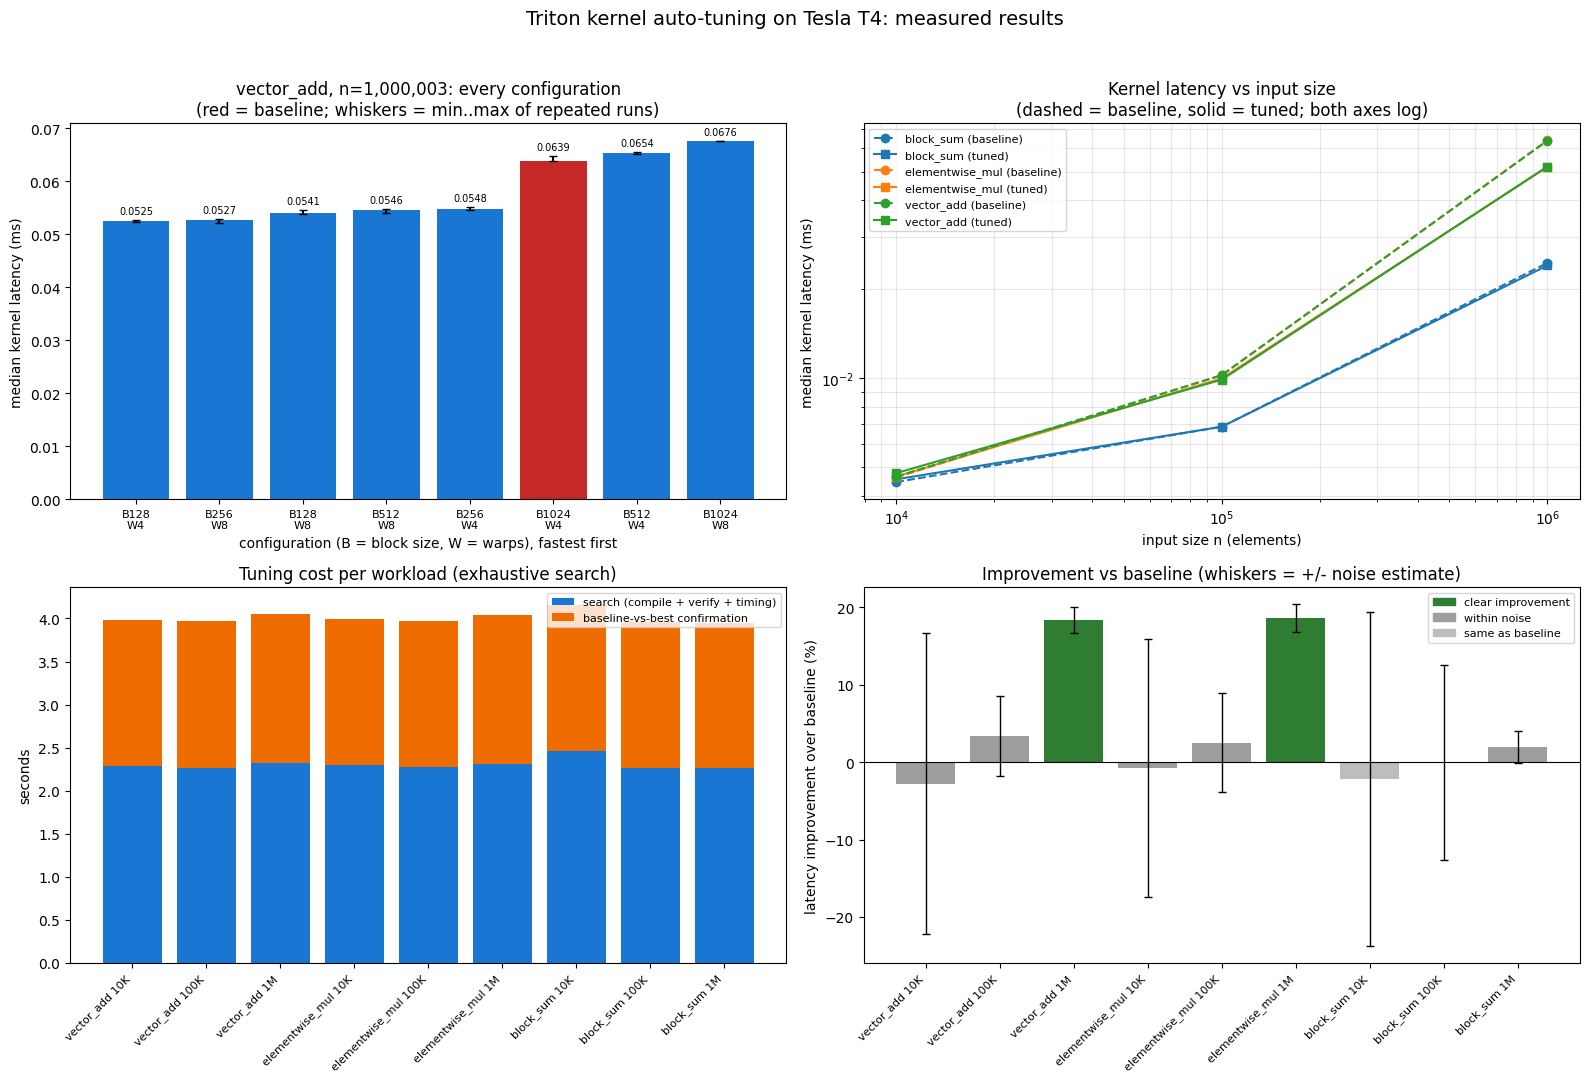

Classified results (run 1):
         kernel       n  best_block  best_warps  baseline_ms  tuned_ms  improvement_pct  noise_pct             label
     vector_add   10000         256           4       0.0046    0.0048          -2.7586    19.4631      within noise
     vector_add  100000         128           4       0.0102    0.0099           3.4375     5.1780      within noise
     vector_add 1000003         128           4       0.0638    0.0521          18.3459     1.6541 clear improvement
elementwise_mul   10000         512           8       0.0046    0.0046          -0.6944    16.6667      within noise
elementwise_mul  100000         128           4       0.0102    0.0100           2.5000     6.4102      within noise
elementwise_mul 1000003         256           8       0.0639    0.0520          18.6373     1.7535 clear improvement
      block_sum   10000        1024           4       0.0044    0.0045          -2.1583    21.5827  same as baseline
      block_sum  100000         256 

# Triton Kernel Auto-Tuning: Experiment Report

_Generated 2026-10-13T07:48:59. Every number below was measured on this GPU; nothing is simulated._

## 1. Setup

- GPU: Tesla T4 (14.56 GB, compute capability 7.5)
- PyTorch 2.11.0+cu130, Triton 3.6.0, Python 3.13.15
- Search algorithm(s): exhaustive. Search space: block size in [128, 256, 512, 1024] x num_warps in [4, 8]
- Timing: `triton.testing.do_bench` (CUDA events, L2 flushed), 25 ms warm-up and 50 ms measurement per run; 5 runs per config in the search (median reported); 15 interleaved runs per config in the final baseline-vs-best comparison
- Baseline: B1024_W4. Improvement % is relative to this choice only.
- Improvement (%) = (baseline latency - tuned latency) / baseline latency x 100, taken from the interleaved head-to-head re-measurement, not from the search phase (this avoids the winner's curse).
- The full sweep was repeated 3 times; section 4 shows whether the winner stayed the same.

![benchmark results](benchmark_results.png)

## 2. Results (run 1)

| kernel | n | best (fastest tested) | baseline ms | tuned ms | improvement | noise | classification |
|---|---|---|---|---|---|---|---|
| vector_add | 10,000 | B256_W4 | 0.0046 | 0.0048 | -2.76% | 19.5% | within noise |
| vector_add | 100,000 | B128_W4 | 0.0102 | 0.0099 | +3.44% | 5.2% | within noise |
| vector_add | 1,000,003 | B128_W4 | 0.0638 | 0.0521 | +18.35% | 1.7% | clear improvement |
| elementwise_mul | 10,000 | B512_W8 | 0.0046 | 0.0046 | -0.69% | 16.7% | within noise |
| elementwise_mul | 100,000 | B128_W4 | 0.0102 | 0.0100 | +2.50% | 6.4% | within noise |
| elementwise_mul | 1,000,003 | B256_W8 | 0.0639 | 0.0520 | +18.64% | 1.8% | clear improvement |
| block_sum | 10,000 | B1024_W4 | 0.0044 | 0.0045 | -2.16% | 21.6% | same as baseline |
| block_sum | 100,000 | B256_W4 | 0.0068 | 0.0068 | +0.00% | 12.6% | within noise |
| block_sum | 1,000,003 | B512_W8 | 0.0246 | 0.0241 | +1.95% | 2.1% | within noise |

Classification rule: noise = max(spread of baseline runs, spread of tuned runs, 1%), where spread = (max - min) / median across repeated runs. `within noise` means |improvement| <= noise; `borderline` means up to 2x noise; `clear` means more than 2x noise.

**Summary:** of 9 workloads, 6 within noise, 2 clear improvement, 1 same as baseline.
Clear improvements: vector_add n=1,000,003 (+18.3%); elementwise_mul n=1,000,003 (+18.6%).
Small inputs (about 10K elements) run for only a few microseconds, so launch overhead and timer resolution dominate and differences there should not be interpreted as tuning gains.

## 3. Near-ties

`best_configurations.json` lists, for each workload, every configuration within 3% of the best search-phase latency. Several configurations are often indistinguishable, so the defensible claim is that a group of configurations is fast, not that one specific configuration is uniquely optimal.

## 4. Run-to-run stability of the winner

| kernel | n | runs | winner per run | improvement % per run | same winner every run |
|---|---|---|---|---|---|
| block_sum | 10,000 | 3 | B1024_W4, B512_W4, B512_W4 | -2.2, +0.0, +1.5 | no |
| block_sum | 100,000 | 3 | B256_W4, B256_W4, B512_W8 | +0.0, -0.5, +0.9 | no |
| block_sum | 1,000,003 | 3 | B512_W8, B512_W4, B512_W4 | +2.0, +1.7, +1.9 | no |
| elementwise_mul | 10,000 | 3 | B512_W8, B1024_W4, B1024_W4 | -0.7, -1.4, +5.3 | no |
| elementwise_mul | 100,000 | 3 | B128_W4, B1024_W4, B128_W4 | +2.5, +1.6, +2.8 | no |
| elementwise_mul | 1,000,003 | 3 | B256_W8, B128_W4, B128_W4 | +18.6, +18.3, +18.5 | no |
| vector_add | 10,000 | 3 | B256_W4, B256_W4, B1024_W4 | -2.8, +0.0, +1.4 | no |
| vector_add | 100,000 | 3 | B128_W4, B256_W8, B512_W4 | +3.4, +2.5, +0.6 | no |
| vector_add | 1,000,003 | 3 | B128_W4, B256_W8, B256_W8 | +18.3, +18.6, +18.2 | no |

9 of 9 workloads had a different winner in at least one run, which is expected when configurations are near-tied.

## 5. Tuning cost, cache reuse and amortization

| kernel | n | search s | confirmation s | cache hit total ms | kernel time saved per launch (us) | break-even launches |
|---|---|---|---|---|---|---|
| vector_add | 10,000 | 2.28 | 1.70 | 4.2 | -0.13 | n/a (no reliable saving) |
| vector_add | 100,000 | 2.27 | 1.70 | 3.3 | +0.35 | n/a (no reliable saving) |
| vector_add | 1,000,003 | 2.32 | 1.73 | 3.9 | +11.71 | 345,608 |
| elementwise_mul | 10,000 | 2.30 | 1.69 | 3.0 | -0.03 | n/a (no reliable saving) |
| elementwise_mul | 100,000 | 2.27 | 1.70 | 3.0 | +0.26 | n/a (no reliable saving) |
| elementwise_mul | 1,000,003 | 2.31 | 1.72 | 3.9 | +11.90 | 339,002 |
| block_sum | 10,000 | 2.46 | 1.69 | 3.0 | -0.10 | n/a (no reliable saving) |
| block_sum | 100,000 | 2.27 | 1.70 | 2.9 | +0.00 | n/a (no reliable saving) |
| block_sum | 1,000,003 | 2.27 | 1.68 | 2.9 | +0.48 | n/a (no reliable saving) |

Break-even = (search + confirmation time) / kernel time saved per launch, shown only for clear improvements. A cache hit reuses a stored configuration and runs one correctness launch; it does not produce a new benchmark measurement. Compile time is only partly included because Triton had cached some kernels earlier in the session.

## 6. Kernel latency vs end-to-end latency

| kernel | n | kernel baseline ms | kernel tuned ms | end-to-end baseline ms | end-to-end tuned ms | end-to-end / kernel (baseline) |
|---|---|---|---|---|---|---|
| vector_add | 10,000 | 0.0046 | 0.0048 | 0.0428 | 0.0426 | 9x |
| vector_add | 100,000 | 0.0102 | 0.0099 | 0.0423 | 0.0419 | 4x |
| vector_add | 1,000,003 | 0.0638 | 0.0521 | 0.1114 | 0.0976 | 2x |
| elementwise_mul | 10,000 | 0.0046 | 0.0046 | 0.1074 | 0.0653 | 23x |
| elementwise_mul | 100,000 | 0.0102 | 0.0100 | 0.0450 | 0.0428 | 4x |
| elementwise_mul | 1,000,003 | 0.0639 | 0.0520 | 0.1338 | 0.1261 | 2x |
| block_sum | 10,000 | 0.0044 | 0.0045 | 0.0467 | 0.0455 | 10x |
| block_sum | 100,000 | 0.0068 | 0.0068 | 0.0450 | 0.0449 | 7x |
| block_sum | 1,000,003 | 0.0246 | 0.0241 | 0.0845 | 0.0965 | 3x |

End-to-end latency includes output allocation, Python launch overhead and GPU synchronization, so it is larger than kernel latency and improves by a smaller percentage. It is a single median over 50 iterations without a spread estimate.

## 7. Limitations

- The selected configuration is the fastest among the valid configurations tested for the given kernel, size and GPU. It is not a proven global optimum.
- Improvement depends on the baseline chosen. A different baseline gives different percentages.
- Measurements come from one shared Colab T4. Clock changes and contention add noise, and results do not transfer to other GPUs (the cache key includes the GPU).
- Spread is a rough noise estimate, not a statistical confidence interval.
- Only float32, one-dimensional memory-bound kernels were tuned. The block-sum kernel tunes the per-block stage only; the final combination of partial sums is not part of the tuned kernel.
- Only block size and warp count are tuned.


In [ ]:
import sys, importlib
sys.path.insert(0, "/content/triton-kernel-autotuner/src")
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

import visualization, report
for m in (visualization, report):
    importlib.reload(m)

from environment import require_gpu
from benchmark import BenchSettings
from tuner import DEFAULT_BASELINE

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)
R = "/content/triton-kernel-autotuner/results/"
env = require_gpu()

# Everything below is computed from the saved measurements of Cell 20
df_rec = pd.read_csv(R + "phase5_raw_records.csv")
df_sum_all = pd.read_csv(R + "phase5_raw_summary.csv")
df_hits = pd.read_csv(R + "phase5_cache_hits.csv")

df_rec_1 = df_rec[df_rec["run"] == 1]
df_sum_1 = report.add_labels(df_sum_all[df_sum_all["run"] == 1])
stab = report.stability_table(df_sum_all)

# ---- 1. Figure
fig = visualization.make_dashboard(df_rec_1, df_sum_1, headline=("vector_add", 1_000_003),
                                   path=R + "benchmark_results.png")
plt.show()

# ---- 2. Tables
print("Classified results (run 1):")
print(df_sum_1[["kernel", "n", "best_block", "best_warps", "baseline_ms", "tuned_ms",
                "improvement_pct", "noise_pct", "label"]].round(4).to_string(index=False))
print("\nWinner stability across runs:")
print(stab.to_string(index=False))

# ---- 3. Exports
df_rec.to_csv(R + "autotune_results.csv", index=False)
entries = report.build_best_configurations(df_sum_1, df_rec_1, stab, env)
report.save_best_configurations(R + "best_configurations.json", entries, env)
text = report.write_report(R + "experiment_report.md", env, df_rec, df_sum_1, stab, df_hits,
                           BenchSettings(), DEFAULT_BASELINE.label())

print("\nSaved: autotune_results.csv, best_configurations.json, benchmark_results.png, "
      "experiment_report.md (autotune_cache.json was written in Cell 20)")
display(Markdown(text))

In [ ]:
import os, shutil
from google.colab import files

R = "/content/triton-kernel-autotuner/results/"
required = ["autotune_results.csv", "autotune_cache.json", "benchmark_results.png",
            "best_configurations.json", "experiment_report.md"]
missing = [f for f in required if not os.path.exists(R + f)]
if missing:
    raise FileNotFoundError(f"Missing {missing}. Run Cells 20 and 21 first.")

shutil.make_archive("/content/autotuner_results", "zip", R)     # one zip avoids multi-download blocking
print(f"Zip created ({os.path.getsize('/content/autotuner_results.zip') / 1024:.0f} KB). Downloading...")
files.download("/content/autotuner_results.zip")

if os.path.isdir("/content/drive/MyDrive"):
    shutil.copytree("/content/triton-kernel-autotuner",
                    "/content/drive/MyDrive/triton-kernel-autotuner", dirs_exist_ok=True)
    print("Backed up to Drive.")
else:
    print("Drive not mounted: run Cell 1 to mount it, then re-run this cell for the backup.")

Zip created (286 KB). Downloading...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Backed up to Drive.
